# 08 · Model Explainability

Why does the final Gradient Boosting model score a client high or low? Three views from lesson 16:

1. **Feature importance**: which features the trees rely on most overall
2. **Partial dependence**: how the predicted probability changes as one feature changes
3. **SHAP values**: how much each feature pushes each individual client's score up or down

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, tree_preprocessor, RANDOM_STATE

from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
best = json.load(open('../results/best_params.json'))
gb_params = {k.replace('model__', ''): v for k, v in best['gradient_boosting'].items()}

final = Pipeline([('prep', tree_preprocessor()),
                  ('model', GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params))]).fit(X_train, y_train)
feature_names = final.named_steps['prep'].get_feature_names_out()
print(len(feature_names), 'features after preprocessing')

47 features after preprocessing


## 1. Feature importance

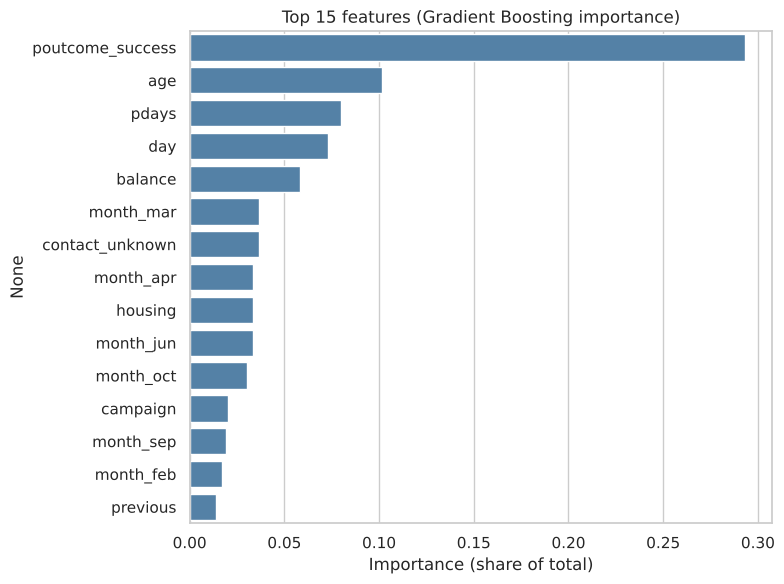

poutcome_success    0.2930
age                 0.1017
pdays               0.0801
day                 0.0730
balance             0.0582
month_mar           0.0368
contact_unknown     0.0368
month_apr           0.0337
housing             0.0337
month_jun           0.0333
month_oct           0.0301
campaign            0.0203
month_sep           0.0193
month_feb           0.0171
previous            0.0140
dtype: float64

In [2]:
imp = (pd.Series(final.named_steps['model'].feature_importances_, index=feature_names)
       .sort_values(ascending=False))
top = imp.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 15 features (Gradient Boosting importance)')
plt.xlabel('Importance (share of total)')
plt.tight_layout(); plt.show()
imp.head(15).round(4)

In [3]:
# importance grouped back to the original columns (one-hot levels summed)
original = {}
for name, value in imp.items():
    base = next((c for c in X_train.columns if name == c or name.startswith(c + '_')), name)
    original[base] = original.get(base, 0) + value
grouped = pd.Series(original).sort_values(ascending=False)
grouped.round(4)

poutcome     0.2998
month        0.2184
age          0.1017
pdays        0.0801
day          0.0730
balance      0.0582
contact      0.0496
housing      0.0337
job          0.0225
campaign     0.0203
previous     0.0140
marital      0.0135
education    0.0086
loan         0.0047
default      0.0019
dtype: float64

## 2. Partial dependence: how the score moves with each feature

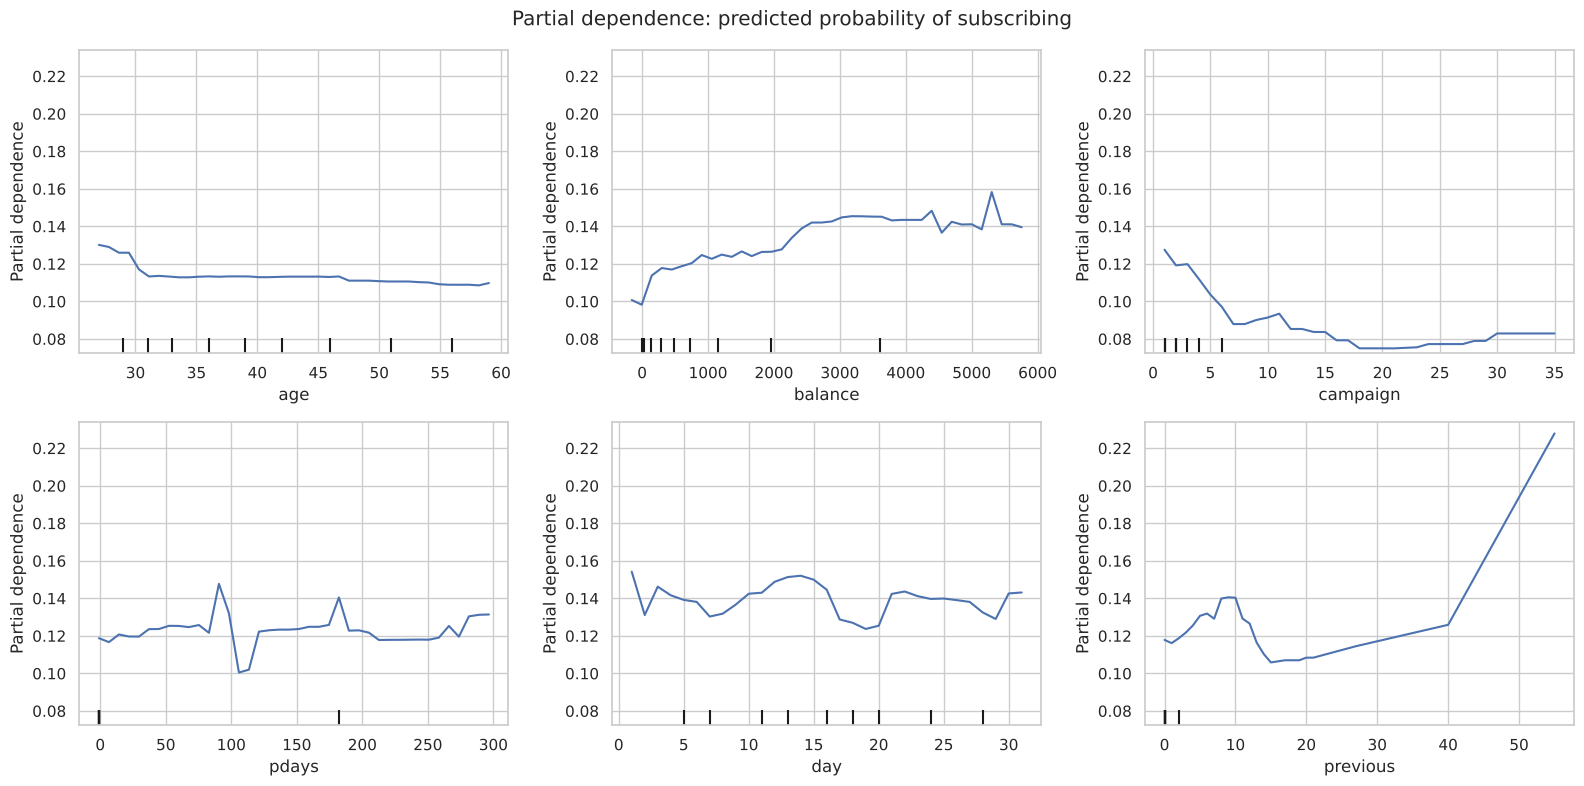

In [4]:
sample = X_train.sample(3000, random_state=RANDOM_STATE)
num = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
sample[num] = sample[num].astype(float)   # partial dependence needs float columns
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
PartialDependenceDisplay.from_estimator(final, sample, ['age', 'balance', 'campaign', 'pdays', 'day', 'previous'],
                                        ax=axes.ravel(), grid_resolution=40)
plt.suptitle('Partial dependence: predicted probability of subscribing')
plt.tight_layout(); plt.show()

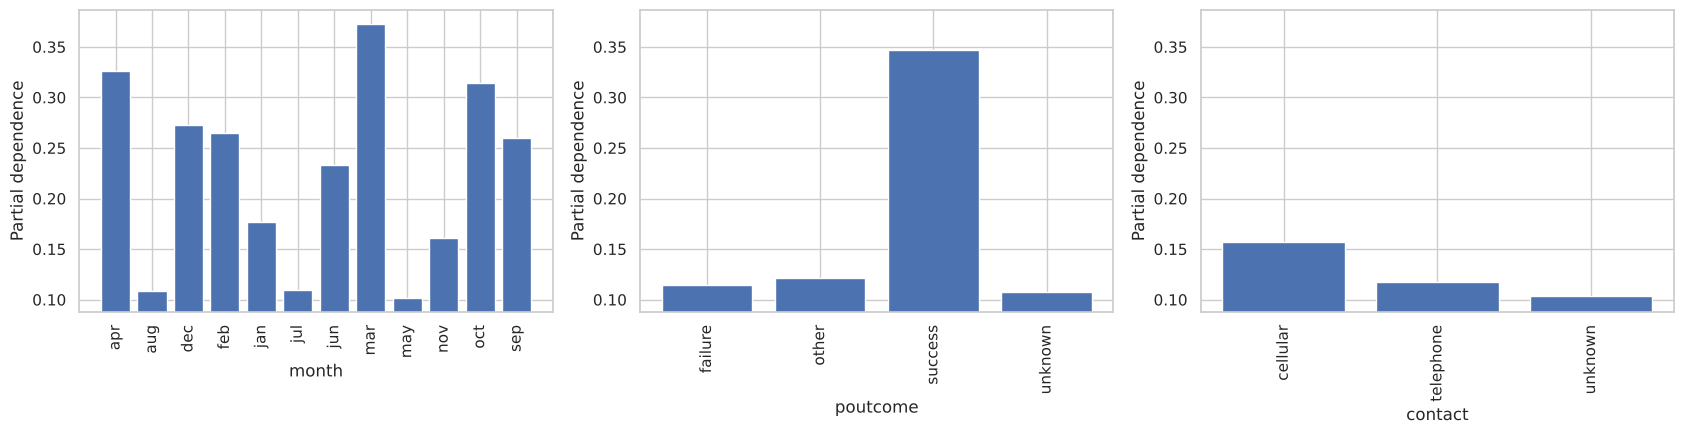

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
PartialDependenceDisplay.from_estimator(final, sample, ['month', 'poutcome', 'contact'],
                                        categorical_features=['month', 'poutcome', 'contact'], ax=axes)
plt.tight_layout(); plt.show()

## 3. SHAP values

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


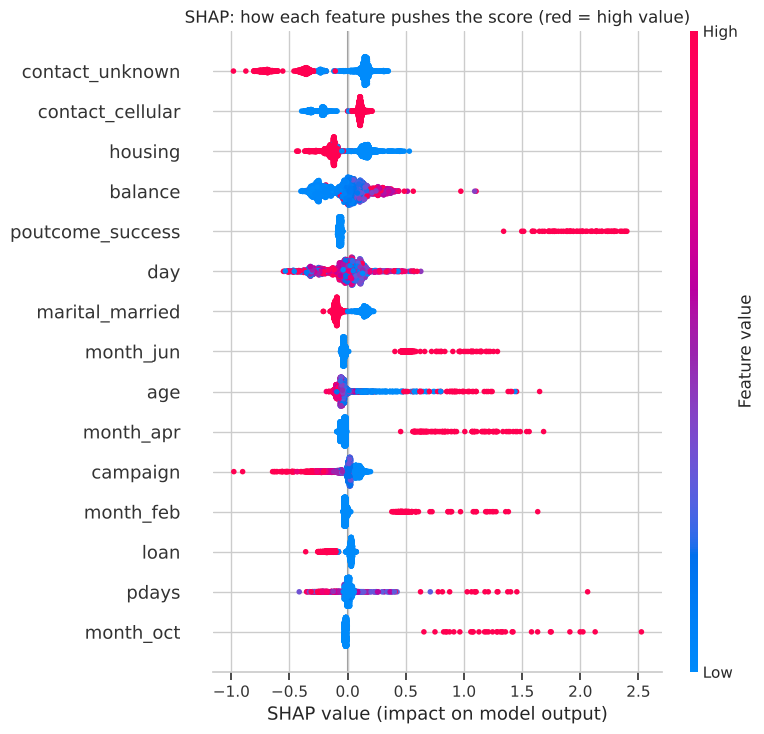

In [6]:
import shap

X_test_t = pd.DataFrame(final.named_steps['prep'].transform(X_test), columns=feature_names)
shap_sample = X_test_t.sample(2000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(final.named_steps['model'])
shap_values = explainer.shap_values(shap_sample)

shap.summary_plot(shap_values, shap_sample, max_display=15, show=False)
plt.title('SHAP: how each feature pushes the score (red = high value)')
plt.tight_layout(); plt.show()

In [7]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)
mean_abs.head(10).round(4)

contact_unknown     0.2504
contact_cellular    0.1585
housing             0.1533
balance             0.1473
poutcome_success    0.1376
day                 0.1254
marital_married     0.1158
month_jun           0.1024
age                 0.0995
month_apr           0.0845
dtype: float64

### One client, explained

In [8]:
proba = final.predict_proba(X_test)[:, 1]
i = int(np.argmax(proba))          # the highest-scored client in the test set
print(f'Predicted probability {proba[i]:.2f} | actually subscribed: {bool(y_test.iloc[i])}')
print(X_test.iloc[i][['age', 'job', 'balance', 'contact', 'month', 'campaign', 'pdays', 'previous', 'poutcome']])
sv = explainer.shap_values(X_test_t.iloc[[i]])[0]
contrib = pd.Series(sv, index=feature_names).sort_values(key=abs, ascending=False).head(8)
contrib.round(3)

Predicted probability 0.92 | actually subscribed: True
age                 30
job         management
balance           5359
contact       cellular
month              feb
campaign             1
pdays              191
previous             3
poutcome       success
Name: 43164, dtype: object


poutcome_success      2.130
month_feb             1.195
day                   0.467
balance               0.439
housing               0.221
education_tertiary    0.113
campaign              0.078
marital_married       0.067
dtype: float64

In [9]:
grouped.round(4).to_csv('../results/feature_importance.csv', header=['importance'])

## What the model learned

**Overall importance** (one-hot levels summed back to their column): `poutcome` **30%** and `month` **22%** dominate, followed by
age 10%, pdays 8%, day 7%, balance 6% and contact 5%. `default` (0.2%), `loan` (0.5%) and `education` (0.9%) barely matter.

**Partial dependence** (average predicted probability as one feature changes):

- **campaign:** about 0.13 at the first call, falling to about 0.09 by the 6th–7th call and flat after that. Extra calls beyond 5–6 add almost nothing.
- **balance:** rises from about 0.10 for zero or negative balances to about 0.145 above roughly €2,500.
- **poutcome:** about **0.35** after a previous success vs about 0.11 for every other outcome.
- **month:** March (0.37), April (0.33) and October (0.31) score highest; May (0.10), July and August (0.11) lowest.
- **contact:** cellular 0.16 vs unknown 0.10.

**SHAP** adds the per-client view. A previous success gives the biggest push of all (up to +2.4 on the log-odds scale) but only for the
3% of clients who have one. Contact "unknown", a housing loan and many campaign calls push scores down for large groups of clients.
The top-scored test client (probability 0.92, and they did subscribe) is driven mainly by `poutcome = success` (+2.13) and a February call (+1.20).

All three views agree with the EDA and with the Logistic Regression odds ratios, so the drivers are consistent across models.